In [21]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
months = ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']

Dados:    
https://dados.ons.org.br/   
https://bdmep.inmet.gov.br/#


# Geração por Usina em Base Horária

In [ ]:
data_geracao = []

for month in months:
  url_geracao = f"https://ons-aws-prod-opendata.s3.amazonaws.com/dataset/geracao_usina_2_ho/GERACAO_USINA-2_2025_{month}.csv"
  df_geracao = pd.read_csv(url_geracao, sep=';')
  data_geracao.append(df_geracao)
df_geracao = pd.concat(data_geracao, ignore_index=True)

In [ ]:
df_geracao.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 6047112 entries, 0 to 6047111
Data columns (total 12 columns):
 #   Column                  Dtype  
---  ------                  -----  
 0   din_instante            object 
 1   id_subsistema           object 
 2   nom_subsistema          object 
 3   id_estado               object 
 4   nom_estado              object 
 5   cod_modalidadeoperacao  object 
 6   nom_tipousina           object 
 7   nom_tipocombustivel     object 
 8   nom_usina               object 
 9   id_ons                  object 
 10  ceg                     object 
 11  val_geracao             float64
dtypes: float64(1), object(11)
memory usage: 553.6+ MB


In [ ]:
df_geracao = df_geracao[df_geracao['nom_usina']=='Conj. Dracena']

In [ ]:
len(df_geracao)

8760

In [ ]:
df_geracao.head()

,din_instante,id_subsistema,nom_subsistema,id_estado,nom_estado,cod_modalidadeoperacao,nom_tipousina,nom_tipocombustivel,nom_usina,id_ons,ceg,val_geracao
623,2025-01-01 00:00:00,SE,SUDESTE,SP,SAO PAULO,Conjunto de Usinas,FOTOVOLTAICA,Fotovoltaica,Conj. Dracena,CJU_SPUFD,-,0.0
1323,2025-01-01 01:00:00,SE,SUDESTE,SP,SAO PAULO,Conjunto de Usinas,FOTOVOLTAICA,Fotovoltaica,Conj. Dracena,CJU_SPUFD,-,0.0
2023,2025-01-01 02:00:00,SE,SUDESTE,SP,SAO PAULO,Conjunto de Usinas,FOTOVOLTAICA,Fotovoltaica,Conj. Dracena,CJU_SPUFD,-,0.0
2723,2025-01-01 03:00:00,SE,SUDESTE,SP,SAO PAULO,Conjunto de Usinas,FOTOVOLTAICA,Fotovoltaica,Conj. Dracena,CJU_SPUFD,-,0.0
3426,2025-01-01 04:00:00,SE,SUDESTE,SP,SAO PAULO,Conjunto de Usinas,FOTOVOLTAICA,Fotovoltaica,Conj. Dracena,CJU_SPUFD,-,0.0


# Dados Meteorológicos

## Dados INMET

In [ ]:
def load_station(estacao):
    path = f"/content/dados_{estacao}_H_2025-01-01_2025-12-31.csv"

    df = pd.read_csv(
        path,
        sep=";",
        skiprows=9,
        decimal=","
    )

    df['Hora Medicao'] = df['Hora Medicao'].astype(str).str.zfill(4)

    df['time'] = df['Hora Medicao'].str[:2] + ":00:00"

    df = df.rename(columns={"Data Medicao": "date"})

    df['data_hora_utc'] = pd.to_datetime(
        df['date'] + ' ' + df['time'],
        format='%Y-%m-%d %H:%M:%S'
    )

    df['datetime'] = df['data_hora_utc'] - pd.Timedelta(hours=3)

    df = df.drop(
        columns=['date', 'time', 'data_hora_utc', 'Hora Medicao'],
        errors='ignore'
    )

    df = df.sort_values('datetime').reset_index(drop=True)

    return df

In [ ]:
df_prudente = load_station('A707')
df_valparaiso = load_station('A734')

In [ ]:
df_dracena = load_station('A762')

In [ ]:
df_dracena.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 22 columns):
 #   Column                                                Non-Null Count  Dtype         
---  ------                                                --------------  -----         
 0   PRECIPITACAO TOTAL, HORARIO(mm)                       6740 non-null   float64       
 1   PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)  6740 non-null   float64       
 2   PRESSAO ATMOSFERICA REDUZIDA NIVEL DO MAR, AUT(mB)    6740 non-null   float64       
 3   PRESSAO ATMOSFERICA MAX.NA HORA ANT. (AUT)(mB)        6740 non-null   float64       
 4   PRESSAO ATMOSFERICA MIN. NA HORA ANT. (AUT)(mB)       6740 non-null   float64       
 5   RADIACAO GLOBAL(Kj/m²)                                6740 non-null   float64       
 6   TEMPERATURA DA CPU DA ESTACAO(°C)                     6740 non-null   float64       
 7   TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)           6740 non-null   float64 

In [ ]:
colunas_analise = [
    'datetime',
    'RADIACAO GLOBAL(Kj/m²)',
    'TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)',
    'TEMPERATURA DO PONTO DE ORVALHO(°C)',
    'UMIDADE RELATIVA DO AR, HORARIA(%)',
    'PRECIPITACAO TOTAL, HORARIO(mm)',
    'VENTO, VELOCIDADE HORARIA(m/s)',
    'VENTO, RAJADA MAXIMA(m/s)',
    'VENTO, DIRECAO HORARIA (gr)(° (gr))',
    'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)'
]

df_analise = df_dracena[colunas_analise].copy()

In [ ]:
df_analise.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 10 columns):
 #   Column                                                Non-Null Count  Dtype         
---  ------                                                --------------  -----         
 0   datetime                                              8760 non-null   datetime64[ns]
 1   RADIACAO GLOBAL(Kj/m²)                                6740 non-null   float64       
 2   TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)           6740 non-null   float64       
 3   TEMPERATURA DO PONTO DE ORVALHO(°C)                   6246 non-null   float64       
 4   UMIDADE RELATIVA DO AR, HORARIA(%)                    6246 non-null   float64       
 5   PRECIPITACAO TOTAL, HORARIO(mm)                       6740 non-null   float64       
 6   VENTO, VELOCIDADE HORARIA(m/s)                        2263 non-null   float64       
 7   VENTO, RAJADA MAXIMA(m/s)                             2263 non-null   float64 

In [ ]:
df_analise = df[df['datetime'].dt.month <= 9].copy()

In [ ]:
df_analise.to_csv('df_analise_dracena.csv', index=False)

In [ ]:
df_analise.describe()

,datetime,RADIACAO GLOBAL(Kj/m²),"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",TEMPERATURA DO PONTO DE ORVALHO(°C),"UMIDADE RELATIVA DO AR, HORARIA(%)","PRECIPITACAO TOTAL, HORARIO(mm)","VENTO, VELOCIDADE HORARIA(m/s)","VENTO, RAJADA MAXIMA(m/s)","VENTO, DIRECAO HORARIA (gr)(° (gr))","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)"
count,8760,6740.000000,6740.000000,6246.000000,6246.000000,6740.000000,2263.000000,2263.000000,2263.000000,6740.000000
mean,2025-07-02 08:30:00,785.213501,23.842433,15.803458,63.717579,0.083086,2.401635,5.309722,146.379585,971.275475
min,2024-12-31 21:00:00,-3.600000,4.300000,-3.200000,11.000000,0.000000,0.200000,0.600000,1.000000,960.400000
25%,2025-04-02 02:45:00,-3.600000,20.400000,12.000000,48.000000,0.000000,1.300000,3.300000,78.000000,968.700000
50%,2025-07-02 08:30:00,8.250000,23.700000,16.100000,64.000000,0.000000,2.200000,5.100000,112.000000,971.100000
75%,2025-10-01 14:15:00,1545.800000,27.500000,20.300000,77.000000,0.000000,3.300000,7.000000,221.500000,973.900000
max,2025-12-31 20:00:00,3947.100000,40.000000,26.400000,100.000000,25.400000,8.900000,21.200000,360.000000,982.300000
std,NaN,1100.639051,5.568583,5.225178,20.868170,0.822574,1.386777,2.641944,98.289610,3.711768


In [ ]:
df_analise.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 10 columns):
 #   Column                                                Non-Null Count  Dtype         
---  ------                                                --------------  -----         
 0   datetime                                              8760 non-null   datetime64[ns]
 1   RADIACAO GLOBAL(Kj/m²)                                6740 non-null   float64       
 2   TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)           6740 non-null   float64       
 3   TEMPERATURA DO PONTO DE ORVALHO(°C)                   6246 non-null   float64       
 4   UMIDADE RELATIVA DO AR, HORARIA(%)                    6246 non-null   float64       
 5   PRECIPITACAO TOTAL, HORARIO(mm)                       6740 non-null   float64       
 6   VENTO, VELOCIDADE HORARIA(m/s)                        2263 non-null   float64       
 7   VENTO, RAJADA MAXIMA(m/s)                             2263 non-null   float64 

In [ ]:
# Valores que normalmente indicam erro/ausência
valores_erro = [
    9999,
    9999.0,
    -9999,
    -9999.0,
    999,
    999.0,
]

colunas = df_analise.select_dtypes(include="number").columns

nan = df_analise[colunas].isna().sum()

erros = (df_analise[colunas].isin(valores_erro)).sum()

resumo = pd.DataFrame({
    "NaN": nan,
    "Valores_erro": erros,
    "Total_suspeitos": nan + erros
})

resumo

,NaN,Valores_erro,Total_suspeitos
RADIACAO GLOBAL(Kj/m²),2020,0,2020
"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",2020,0,2020
TEMPERATURA DO PONTO DE ORVALHO(°C),2514,0,2514
"UMIDADE RELATIVA DO AR, HORARIA(%)",2514,0,2514
"PRECIPITACAO TOTAL, HORARIO(mm)",2020,0,2020
"VENTO, VELOCIDADE HORARIA(m/s)",6497,0,6497
"VENTO, RAJADA MAXIMA(m/s)",6497,0,6497
"VENTO, DIRECAO HORARIA (gr)(° (gr))",6497,0,6497
"PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",2020,0,2020


In [ ]:
df_analise["data"] = df_analise["datetime"].dt.date

temperatura = "TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)"

problemas_dia = (
    df_analise.groupby("data")[temperatura]
      .apply(lambda x: x.isna().sum() + x.isin(valores_erro).sum())
)

problemas_dia = problemas_dia[problemas_dia > 0]

problemas_dia

,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)"
data,
2025-10-08,7
2025-10-09,24
2025-10-10,24
2025-10-11,24
2025-10-12,24
...,...
2025-12-27,24
2025-12-28,24
2025-12-29,24


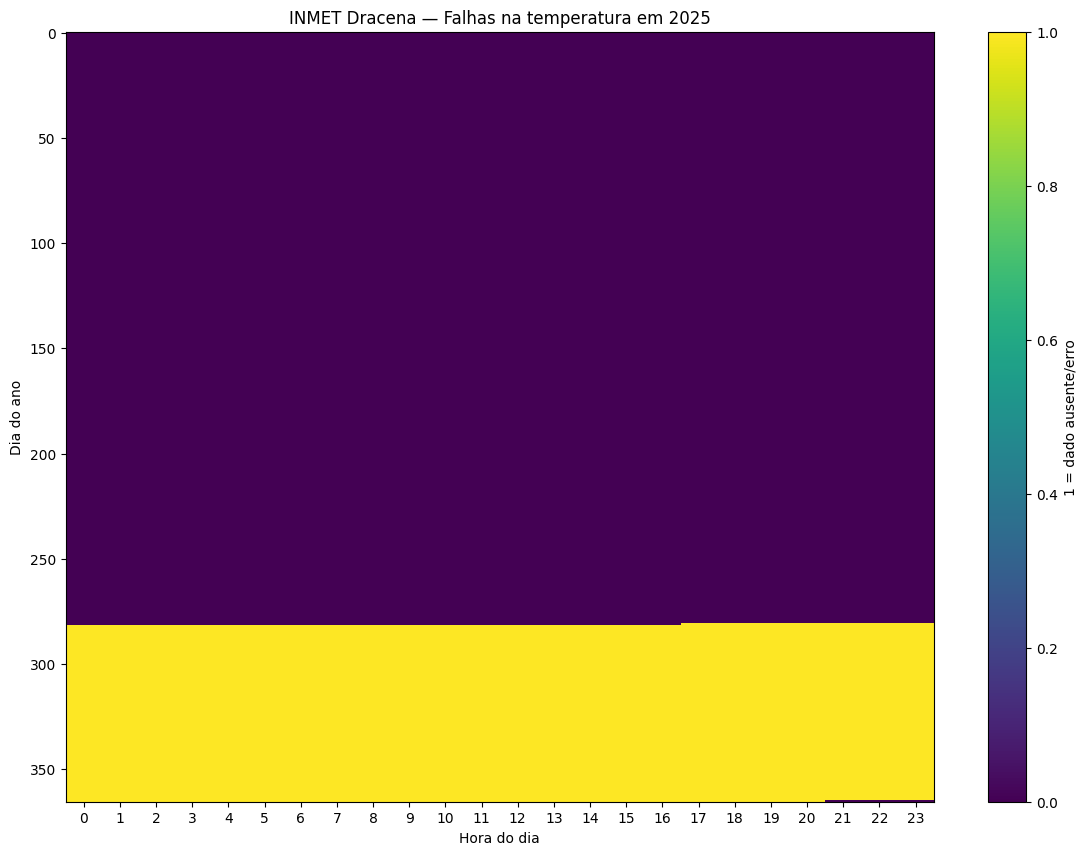

In [ ]:
df_analise["problema_temp"] = (
    df_analise[temperatura].isna() |
    df_analise[temperatura].isin(valores_erro)
)

# matriz dia x hora
matriz = df_analise.pivot_table(
    index=df_analise["datetime"].dt.date,
    columns=df_analise["datetime"].dt.hour,
    values="problema_temp",
    aggfunc="max",
    fill_value=False
)

# Garantir que seja numérica
matriz = matriz.astype(float)

plt.figure(figsize=(14, 10))

plt.imshow(
    matriz,
    aspect="auto",
    interpolation="none"
)

plt.xlabel("Hora do dia")
plt.ylabel("Dia do ano")
plt.title("INMET Dracena — Falhas na temperatura em 2025")

plt.colorbar(label="1 = dado ausente/erro")

plt.xticks(range(24), range(24))

plt.show()

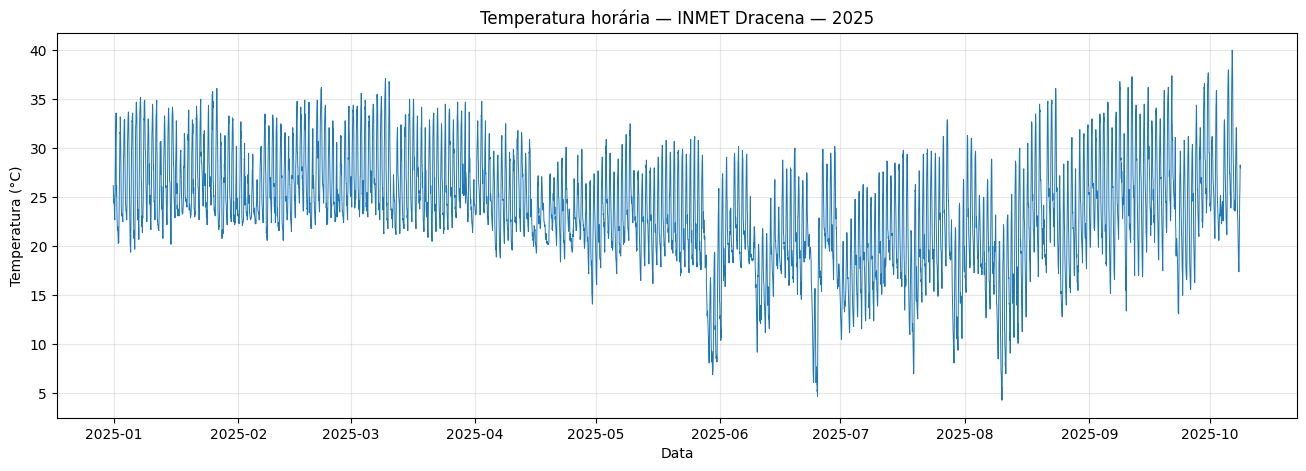

In [ ]:
plt.figure(figsize=(16, 5))

plt.plot(
    df_analise["datetime"],
    df_analise[temperatura],
    linewidth=0.7
)

plt.xlabel("Data")
plt.ylabel("Temperatura (°C)")
plt.title("Temperatura horária — INMET Dracena — 2025")

plt.grid(True, alpha=0.3)

plt.show()

In [ ]:
df_analise["delta_temp"] = df_analise[temperatura].diff()

suspeitos = df_analise[
    df_analise["delta_temp"].abs() > 5
][[
    "datetime",
    temperatura,
    "delta_temp"
]]

suspeitos

,datetime,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",delta_temp
18,2025-01-01 15:00:00,25.5,-8.1
263,2025-01-11 20:00:00,23.0,-6.3
380,2025-01-16 17:00:00,25.4,-5.6
454,2025-01-19 19:00:00,23.7,-5.9
477,2025-01-20 18:00:00,25.8,-6.7
597,2025-01-25 18:00:00,26.7,-8.1
718,2025-01-30 19:00:00,23.1,-8.2
810,2025-02-03 15:00:00,24.4,-5.1
980,2025-02-10 17:00:00,23.1,-7.9
1100,2025-02-15 17:00:00,29.6,-5.2


In [ ]:
df_analise["delta_horas"] = (
    df_analise["datetime"].diff()
    .dt.total_seconds()
    / 3600
)

In [ ]:
df_analise["delta_temp"] = (
    df_analise[temperatura].diff()
)

In [ ]:
suspeitos = df_analise[
    (df_analise["delta_horas"] == 1) &
    (df_analise["delta_temp"].abs() > 5)
][[
    "datetime",
    temperatura,
    "delta_temp",
    "delta_horas"
]]

In [ ]:
suspeitos

,datetime,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",delta_temp,delta_horas
18,2025-01-01 15:00:00,25.5,-8.1,1.0
263,2025-01-11 20:00:00,23.0,-6.3,1.0
380,2025-01-16 17:00:00,25.4,-5.6,1.0
454,2025-01-19 19:00:00,23.7,-5.9,1.0
477,2025-01-20 18:00:00,25.8,-6.7,1.0
597,2025-01-25 18:00:00,26.7,-8.1,1.0
718,2025-01-30 19:00:00,23.1,-8.2,1.0
810,2025-02-03 15:00:00,24.4,-5.1,1.0
980,2025-02-10 17:00:00,23.1,-7.9,1.0
1100,2025-02-15 17:00:00,29.6,-5.2,1.0


In [ ]:
col_temp = 'TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)'

df_analise = df_analise.sort_values('datetime').reset_index(drop=True)

df_analise['T_-3h'] = df_analise[col_temp].shift(3)
df_analise['T_-2h'] = df_analise[col_temp].shift(2)
df_analise['T_-1h'] = df_analise[col_temp].shift(1)
df_analise['T_0h'] = df_analise[col_temp]
df_analise['T_+1h'] = df_analise[col_temp].shift(-1)
df_analise['T_+2h'] = df_analise[col_temp].shift(-2)
df_analise['T_+3h'] = df_analise[col_temp].shift(-3)

df_analise['delta_temp'] = df_analise['T_0h'] - df_analise['T_-1h']

cols_janela = [
    'datetime',
    'T_-3h',
    'T_-2h',
    'T_-1h',
    'T_0h',
    'T_+1h',
    'T_+2h',
    'T_+3h',
    'delta_temp',
]

ausentes_isolados = df_analise[
    (df_analise['datetime'] < '2025-10-08') & (df_analise['T_0h'].isna())
][cols_janela]

salto_entrando = df_analise['T_0h'] - df_analise['T_-1h']
salto_saindo = df_analise['T_+1h'] - df_analise['T_0h']

cond_v_shape = (
    (salto_entrando.abs() >= 5.0)
    & (salto_saindo.abs() >= 5.0)
    & ((salto_entrando * salto_saindo) < 0)
)

cond_salto = df_analise['delta_temp'].abs() >= 5.0

anomalias_temp = df_analise[
    (df_analise['datetime'] < '2025-10-08') & (cond_salto | cond_v_shape)
].copy()

anomalias_temp['diag_preliminar'] = np.where(
    cond_v_shape[anomalias_temp.index],
    'Erro de Sensor (V-shape)',
    np.where(
        anomalias_temp['delta_temp'] < 0,
        'Queda Abrupta (>5°C/h)',
        'Aumento Abrupto (>5°C/h)',
    ),
)

print(
    f"--- HORAS FALTANTES ISOLADAS PRÉ-OUTUBRO: {len(ausentes_isolados)} ---"
)
display(ausentes_isolados)

print(f"\n--- ANOMALIAS E SALTOS TÉRMICOS: {len(anomalias_temp)} ---")
display(anomalias_temp[cols_janela + ['diag_preliminar']])

--- HORAS FALTANTES ISOLADAS PRÉ-OUTUBRO: 0 ---


,datetime,T_-3h,T_-2h,T_-1h,T_0h,T_+1h,T_+2h,T_+3h,delta_temp



--- ANOMALIAS E SALTOS TÉRMICOS: 29 ---


,datetime,T_-3h,T_-2h,T_-1h,T_0h,T_+1h,T_+2h,T_+3h,delta_temp,diag_preliminar
18,2025-01-01 15:00:00,32.1,33.2,33.6,25.5,25.1,26.2,24.7,-8.1,Queda Abrupta (>5°C/h)
263,2025-01-11 20:00:00,34.9,30.1,29.3,23.0,22.7,22.3,22.2,-6.3,Queda Abrupta (>5°C/h)
380,2025-01-16 17:00:00,32.8,32.1,31.0,25.4,26.4,23.8,24.2,-5.6,Queda Abrupta (>5°C/h)
454,2025-01-19 19:00:00,33.9,33.1,29.6,23.7,24.1,24.2,24.3,-5.9,Queda Abrupta (>5°C/h)
477,2025-01-20 18:00:00,32.4,31.5,32.5,25.8,25.4,26.8,25.6,-6.7,Queda Abrupta (>5°C/h)
597,2025-01-25 18:00:00,35.8,34.1,34.8,26.7,26.5,26.1,25.1,-8.1,Queda Abrupta (>5°C/h)
718,2025-01-30 19:00:00,33.0,31.8,31.3,23.1,23.3,24.6,22.5,-8.2,Queda Abrupta (>5°C/h)
810,2025-02-03 15:00:00,26.4,28.2,29.5,24.4,25.1,24.7,25.2,-5.1,Queda Abrupta (>5°C/h)
980,2025-02-10 17:00:00,33.1,32.6,31.0,23.1,23.2,23.9,23.0,-7.9,Queda Abrupta (>5°C/h)
1100,2025-02-15 17:00:00,33.5,34.2,34.8,29.6,29.6,28.5,28.1,-5.2,Queda Abrupta (>5°C/h)


In [ ]:
col_precip = 'PRECIPITACAO TOTAL, HORARIO(mm)'

# Cruzar as anomalias de queda com a precipitação da mesma hora
validacao_chuva = anomalias_temp[
    anomalias_temp['diag_preliminar'] == 'Queda Abrupta (>5°C/h)'
][['datetime', 'T_-1h', 'T_0h', 'delta_temp']].merge(
    df_analise[['datetime', col_precip]], on='datetime', how='left'
)

display(validacao_chuva.head(10))

,datetime,T_-1h,T_0h,delta_temp,"PRECIPITACAO TOTAL, HORARIO(mm)"
0,2025-01-01 15:00:00,33.6,25.5,-8.1,0.0
1,2025-01-11 20:00:00,29.3,23.0,-6.3,0.4
2,2025-01-16 17:00:00,31.0,25.4,-5.6,0.8
3,2025-01-19 19:00:00,29.6,23.7,-5.9,4.2
4,2025-01-20 18:00:00,32.5,25.8,-6.7,0.0
5,2025-01-25 18:00:00,34.8,26.7,-8.1,0.0
6,2025-01-30 19:00:00,31.3,23.1,-8.2,11.6
7,2025-02-03 15:00:00,29.5,24.4,-5.1,11.2
8,2025-02-10 17:00:00,31.0,23.1,-7.9,4.2
9,2025-02-15 17:00:00,34.8,29.6,-5.2,0.0


In [ ]:
display(validacao_chuva.head(24))

,datetime,T_-1h,T_0h,delta_temp,"PRECIPITACAO TOTAL, HORARIO(mm)"
0,2025-01-01 15:00:00,33.6,25.5,-8.1,0.0
1,2025-01-11 20:00:00,29.3,23.0,-6.3,0.4
2,2025-01-16 17:00:00,31.0,25.4,-5.6,0.8
3,2025-01-19 19:00:00,29.6,23.7,-5.9,4.2
4,2025-01-20 18:00:00,32.5,25.8,-6.7,0.0
5,2025-01-25 18:00:00,34.8,26.7,-8.1,0.0
6,2025-01-30 19:00:00,31.3,23.1,-8.2,11.6
7,2025-02-03 15:00:00,29.5,24.4,-5.1,11.2
8,2025-02-10 17:00:00,31.0,23.1,-7.9,4.2
9,2025-02-15 17:00:00,34.8,29.6,-5.2,0.0


In [ ]:
len(validacao_chuva)

24

In [ ]:
# Verificar se a chuva ocorreu na hora posterior ao salto térmico
validacao_completa = anomalias_temp[
    anomalias_temp['diag_preliminar'] == 'Queda Abrupta (>5°C/h)'
][['datetime', 'T_-1h', 'T_0h', 'delta_temp']].copy()

validacao_completa['precip_T0'] = df_analise.loc[
    validacao_completa.index, col_precip
].values
validacao_completa['precip_T+1h'] = df_analise.loc[
    validacao_completa.index + 1, col_precip
].values

display(
    validacao_completa[validacao_completa['precip_T0'] == 0][
        ['datetime', 'delta_temp', 'precip_T0', 'precip_T+1h']
    ]
)

,datetime,delta_temp,precip_T0,precip_T+1h
18,2025-01-01 15:00:00,-8.1,0.0,1.0
477,2025-01-20 18:00:00,-6.7,0.0,0.0
597,2025-01-25 18:00:00,-8.1,0.0,0.0
1100,2025-02-15 17:00:00,-5.2,0.0,0.0
1318,2025-02-24 19:00:00,-5.5,0.0,0.0
1510,2025-03-04 19:00:00,-7.9,0.0,0.0
3477,2025-05-25 18:00:00,-6.2,0.0,0.0
4054,2025-06-18 19:00:00,-5.4,0.0,0.0
4798,2025-07-19 19:00:00,-5.5,0.0,0.0
6350,2025-09-22 11:00:00,-6.8,0.0,1.6


In [ ]:
col_rad = 'RADIACAO GLOBAL(Kj/m²)'

# 1. Ordenação cronológica e extração da hora
df_analise = df_analise.sort_values('datetime').reset_index(drop=True)
df_analise['hora'] = df_analise['datetime'].dt.hour

# 2. Testes de Consistência Física (Apenas até 07/10/2025)
filtro_pre_outubro = df_analise['datetime'] < '2025-10-08'

# Teste 1: Faltantes
rad_faltantes = df_analise[filtro_pre_outubro & df_analise[col_rad].isna()]

# Teste 2: Valores Negativos
rad_negativa = df_analise[filtro_pre_outubro & (df_analise[col_rad] < 0)]

# Teste 3: Radiação Noturna (Horizonte Noturno em UTC: ~22h UTC às 08h UTC)
# Em UTC-3 (horário de Brasília), 22h-08h UTC corresponde a 19h-05h locais.
horas_noite_utc = [22, 23, 0, 1, 2, 3, 4, 5, 6, 7, 8]
rad_noturna = df_analise[
    filtro_pre_outubro
    & df_analise['hora'].isin(horas_noite_utc)
    & (df_analise[col_rad] > 0)
]

# Teste 4: Valores Extremos (Acima do limite físico razoável na superfície)
rad_extrema = df_analise[filtro_pre_outubro & (df_analise[col_rad] > 4200)]

# --- EXIBIÇÃO DOS RESULTADOS ---
print(
    f"1. Horas faltantes pré-outubro: {len(rad_faltantes)}"
)
print(f"2. Registros negativos (< 0): {len(rad_negativa)}")
print(
    f"3. Registros noturnos anômalos (> 0 à noite): {len(rad_noturna)}"
)
print(f"4. Registros extremamente altos (> 4200 kJ/m²): {len(rad_extrema)}")

print("\n--- PERFIL MÉDIO DE RADIAÇÃO POR HORA UTC (kJ/m²) ---")
perfil_horario = (
    df_analise[filtro_pre_outubro].groupby('hora')[col_rad].mean().round(1)
)
print(perfil_horario)

1. Horas faltantes pré-outubro: 0
2. Registros negativos (< 0): 3206
3. Registros noturnos anômalos (> 0 à noite): 500
4. Registros extremamente altos (> 4200 kJ/m²): 0

--- PERFIL MÉDIO DE RADIAÇÃO POR HORA UTC (kJ/m²) ---
hora
0       -3.3
1       -3.4
2       -3.3
3       -3.3
4       -3.3
5       -3.3
6       -3.0
7       47.5
8      418.2
9     1056.0
10    1748.0
11    2298.4
12    2639.6
13    2735.2
14    2592.0
15    2155.8
16    1666.5
17    1071.1
18     408.2
19      50.6
20      -2.5
21      -3.4
22      -3.3
23      -3.3
Name: RADIACAO GLOBAL(Kj/m²), dtype: float64


In [ ]:
df_dracena.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 22 columns):
 #   Column                                                Non-Null Count  Dtype         
---  ------                                                --------------  -----         
 0   PRECIPITACAO TOTAL, HORARIO(mm)                       6740 non-null   float64       
 1   PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)  6740 non-null   float64       
 2   PRESSAO ATMOSFERICA REDUZIDA NIVEL DO MAR, AUT(mB)    6740 non-null   float64       
 3   PRESSAO ATMOSFERICA MAX.NA HORA ANT. (AUT)(mB)        6740 non-null   float64       
 4   PRESSAO ATMOSFERICA MIN. NA HORA ANT. (AUT)(mB)       6740 non-null   float64       
 5   RADIACAO GLOBAL(Kj/m²)                                6740 non-null   float64       
 6   TEMPERATURA DA CPU DA ESTACAO(°C)                     6740 non-null   float64       
 7   TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)           6740 non-null   float64 

## Comparar Radiação INMET e CAMS

In [ ]:
df_cams = pd.read_csv("/content/19a05502a368e87194e82d7d5fb5dadb.csv", sep=';', comment="#",na_values="nan")

In [ ]:
df_cams.head(-3)

,TOA,Clear sky GHI,Clear sky BHI,Clear sky DHI,Clear sky BNI,ghi,bhi,dhi,bni,reliability,inicio,fim
0,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0,2025-01-01 00:00:00,2025-01-01 01:00:00
1,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0,2025-01-01 01:00:00,2025-01-01 02:00:00
2,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0,2025-01-01 02:00:00,2025-01-01 03:00:00
3,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0,2025-01-01 03:00:00,2025-01-01 04:00:00
4,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,0.0000,1.0,2025-01-01 04:00:00,2025-01-01 05:00:00
...,...,...,...,...,...,...,...,...,...,...,...,...
8752,1362.2117,1044.3887,950.6957,93.6929,982.4510,469.8433,147.9028,321.9405,150.1869,1.0,2025-12-31 16:00:00,2025-12-31 17:00:00
8753,1241.5494,941.2623,850.3425,90.9199,963.9272,78.2955,0.0000,78.2955,0.0000,1.0,2025-12-31 17:00:00,2025-12-31 18:00:00
8754,1050.0405,778.2439,691.1573,87.0865,925.7091,69.1828,0.0000,69.1828,0.0000,1.0,2025-12-31 18:00:00,2025-12-31 19:00:00
8755,800.7268,568.8043,488.1207,80.6836,855.5610,80.7108,0.0000,80.7108,0.0000,1.0,2025-12-31 19:00:00,2025-12-31 20:00:00


In [ ]:
df_cams[["inicio", "fim"]] = df_cams["Observation period"].str.split("/", expand=True)

df_cams["inicio"] = pd.to_datetime(df_cams["inicio"])
df_cams["fim"] = pd.to_datetime(df_cams["fim"])

df_cams = df_cams.drop(columns=["Observation period"])

df_cams = df_cams.rename(columns={
    "GHI": "ghi",
    "BHI": "bhi",
    "DHI": "dhi",
    "BNI": "bni",
    "Reliability": "reliability"
})

df_cams.head()

,TOA,Clear sky GHI,Clear sky BHI,Clear sky DHI,Clear sky BNI,ghi,bhi,dhi,bni,reliability,inicio,fim
0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2025-01-01 00:00:00,2025-01-01 01:00:00
1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2025-01-01 01:00:00,2025-01-01 02:00:00
2,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2025-01-01 02:00:00,2025-01-01 03:00:00
3,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2025-01-01 03:00:00,2025-01-01 04:00:00
4,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,1.0,2025-01-01 04:00:00,2025-01-01 05:00:00


In [ ]:
def processar_e_imputar_radiacao_ajustado(
    df_analise,
    df_cams,
    col_rad_inmet='RADIACAO GLOBAL(Kj/m²)',
    horas_deslocamento=2,
):
    inmet = df_analise.copy()
    cams = df_cams.copy()

    # 1. Ajuste de fuso/timestamp no INMET para alinhar ao UTC do CAMS
    inmet['datetime_utc'] = pd.to_datetime(
        inmet['datetime']
    ) + pd.Timedelta(hours=horas_deslocamento)

    # 2. Padronização de data no CAMS
    if 'inicio' in cams.columns:
        cams['datetime_utc'] = pd.to_datetime(cams['inicio'])
    elif 'Observation period' in cams.columns:
        cams['datetime_utc'] = pd.to_datetime(
            cams['Observation period'].str.split('/').str[0]
        )
    else:
        cams['datetime_utc'] = pd.to_datetime(cams['datetime'])

    # 3. Conversão de unidades: CAMS (Wh/m²) -> INMET (kJ/m²)
    col_cams_ghi = (
        'ghi'
        if 'ghi' in cams.columns
        else ('GHI' if 'GHI' in cams.columns else 'ghi_wh')
    )
    cams['rad_cams_kj'] = cams[col_cams_ghi] * 3.6

    # 4. Tratamento do Zero-Drift no INMET
    inmet['rad_inmet_tratada'] = inmet[col_rad_inmet].clip(lower=0)

    # 5. Merge sincronizado em UTC
    df_merged = pd.merge(
        inmet,
        cams[['datetime_utc', 'rad_cams_kj']],
        on='datetime_utc',
        how='left',
    )

    # 6. Avaliação de desempenho pré-outubro (Apenas período diurno)
    filtro_val = (
        (df_merged['datetime_utc'] < '2025-10-08')
        & (df_merged['rad_cams_kj'] > 5)
        & (df_merged['rad_inmet_tratada'].notna())
    )

    val_data = df_merged[filtro_val]
    y_inmet = val_data['rad_inmet_tratada']
    y_cams = val_data['rad_cams_kj']

    metricas = {
        'MBE (kJ/m²)': round((y_cams - y_inmet).mean(), 2),
        'MAE (kJ/m²)': round((y_cams - y_inmet).abs().mean(), 2),
        'RMSE (kJ/m²)': round(np.sqrt(((y_cams - y_inmet) ** 2).mean()), 2),
        'R²': round(np.corrcoef(y_cams, y_inmet)[0, 1] ** 2, 4),
    }

    # 7. Imputação dos dados faltantes de Out/2025 a Dez/2025
    df_merged['RADIACAO_FINAL(Kj/m²)'] = df_merged[
        'rad_inmet_tratada'
    ].fillna(df_merged['rad_cams_kj'])
    df_merged['origem_radiacao'] = np.where(
        df_merged[col_rad_inmet].notna(), 'INMET_A762', 'CAMS_Imputado'
    )

    return df_merged, metricas


df_final, metricas_ajustadas = processar_e_imputar_radiacao_ajustado(
    df_analise, df_cams
)

In [ ]:
df_final

,datetime,RADIACAO GLOBAL(Kj/m²),"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",TEMPERATURA DO PONTO DE ORVALHO(°C),"UMIDADE RELATIVA DO AR, HORARIA(%)","PRECIPITACAO TOTAL, HORARIO(mm)","VENTO, VELOCIDADE HORARIA(m/s)","VENTO, RAJADA MAXIMA(m/s)","VENTO, DIRECAO HORARIA (gr)(° (gr))","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",...,T_0h,T_+1h,T_+2h,T_+3h,hora,datetime_utc,rad_inmet_tratada,rad_cams_kj,RADIACAO_FINAL(Kj/m²),origem_radiacao
0,2024-12-31 21:00:00,-3.6,26.2,20.2,69.0,0.0,1.7,5.3,86.0,965.1,...,26.2,25.1,25.2,25.2,21,2024-12-31 23:00:00,0.0,NaN,0.00000,INMET_A762
1,2024-12-31 22:00:00,-3.6,25.1,19.5,71.0,0.0,2.3,3.3,79.0,965.7,...,25.1,25.2,25.2,24.4,22,2025-01-01 00:00:00,0.0,0.00000,0.00000,INMET_A762
2,2024-12-31 23:00:00,-3.6,25.2,19.4,70.0,0.0,1.7,3.3,113.0,966.4,...,25.2,25.2,24.4,24.9,23,2025-01-01 01:00:00,0.0,0.00000,0.00000,INMET_A762
3,2025-01-01 00:00:00,-3.6,25.2,19.6,71.0,0.0,1.8,3.1,126.0,966.4,...,25.2,24.4,24.9,24.1,0,2025-01-01 02:00:00,0.0,0.00000,0.00000,INMET_A762
4,2025-01-01 01:00:00,-3.6,24.4,20.2,78.0,0.0,1.5,3.1,91.0,966.1,...,24.4,24.9,24.1,23.4,1,2025-01-01 03:00:00,0.0,0.00000,0.00000,INMET_A762
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8755,2025-12-31 16:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,16,2025-12-31 18:00:00,NaN,249.05808,249.05808,CAMS_Imputado
8756,2025-12-31 17:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,17,2025-12-31 19:00:00,NaN,290.55888,290.55888,CAMS_Imputado
8757,2025-12-31 18:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,18,2025-12-31 20:00:00,NaN,222.16896,222.16896,CAMS_Imputado
8758,2025-12-31 19:00:00,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,19,2025-12-31 21:00:00,NaN,92.62296,92.62296,CAMS_Imputado


In [ ]:
print(metricas_ajustadas)

{'MBE (kJ/m²)': np.float64(21.13), 'MAE (kJ/m²)': np.float64(149.04), 'RMSE (kJ/m²)': np.float64(253.08), 'R²': np.float64(0.9485)}


In [ ]:
df_analise.head()

,datetime,RADIACAO GLOBAL(Kj/m²),"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",TEMPERATURA DO PONTO DE ORVALHO(°C),"UMIDADE RELATIVA DO AR, HORARIA(%)","PRECIPITACAO TOTAL, HORARIO(mm)","VENTO, VELOCIDADE HORARIA(m/s)","VENTO, RAJADA MAXIMA(m/s)","VENTO, DIRECAO HORARIA (gr)(° (gr))","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",...,salto_anterior,salto_posterior,T_-3h,T_-2h,T_-1h,T_0h,T_+1h,T_+2h,T_+3h,hora
0,2024-12-31 21:00:00,-3.6,26.2,20.2,69.0,0.0,1.7,5.3,86.0,965.1,...,NaN,-1.1,NaN,NaN,NaN,26.2,25.1,25.2,25.2,21
1,2024-12-31 22:00:00,-3.6,25.1,19.5,71.0,0.0,2.3,3.3,79.0,965.7,...,-1.1,0.1,NaN,NaN,26.2,25.1,25.2,25.2,24.4,22
2,2024-12-31 23:00:00,-3.6,25.2,19.4,70.0,0.0,1.7,3.3,113.0,966.4,...,0.1,0.0,NaN,26.2,25.1,25.2,25.2,24.4,24.9,23
3,2025-01-01 00:00:00,-3.6,25.2,19.6,71.0,0.0,1.8,3.1,126.0,966.4,...,0.0,-0.8,26.2,25.1,25.2,25.2,24.4,24.9,24.1,0
4,2025-01-01 01:00:00,-3.6,24.4,20.2,78.0,0.0,1.5,3.1,91.0,966.1,...,-0.8,0.5,25.1,25.2,25.2,24.4,24.9,24.1,23.4,1


## Comparação Dracena ValParaiso PresidentePrudente

In [ ]:
def analisar_estacoes_vizinhas(df_dracena, df_prudente, df_valparaiso):

    for df in [df_dracena, df_prudente, df_valparaiso]:
        df['datetime_utc'] = pd.to_datetime(df['datetime'])

    df_comp = pd.merge(
        df_dracena,
        df_prudente,
        on='datetime_utc',
        suffixes=('', '_prudente'),
        how='inner',
    )
    df_comp = pd.merge(
        df_comp,
        df_valparaiso,
        on='datetime_utc',
        suffixes=('_dracena', '_valparaiso'),
        how='inner',
    )

    # Pesos por Inverso da Distância (IDW)
    d_prudente, d_valparaiso = 76.42, 69.68
    w_prudente = (1 / d_prudente) / ((1 / d_prudente) + (1 / d_valparaiso))
    w_valparaiso = (1 / d_valparaiso) / ((1 / d_prudente) + (1 / d_valparaiso))

    variaveis = [
        ('TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)', 'Temperatura (°C)'),
        ('UMIDADE RELATIVA DO AR, HORARIA(%)', 'Umidade (%)'),
        (
            'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)',
            'Pressão (mB)',
        ),
        ('VENTO, VELOCIDADE HORARIA(m/s)', 'Vento (m/s)'),
        ('PRECIPITACAO TOTAL, HORARIO(mm)', 'Chuva (mm)'),
    ]

    resultados = []

    for col_base, nome_var in variaveis:
        col_dra = (
            col_base
            if col_base in df_comp.columns
            else f'{col_base}_dracena'
        )
        col_pru = f'{col_base}_prudente'
        col_val = f'{col_base}_valparaiso'

        # Filtrar registros válidos simultâneos em Jan-Out
        df_sub = df_comp[
            (df_comp['datetime_utc'] < '2025-10-08')
            & df_comp[col_dra].notna()
            & df_comp[col_pru].notna()
            & df_comp[col_val].notna()
        ]

        y_true = df_sub[col_dra]
        y_pru = df_sub[col_pru]
        y_val = df_sub[col_val]
        y_idw = (y_pru * w_prudente) + (y_val * w_valparaiso)

        for fonte, y_pred in [
            ('Prudente', y_pru),
            ('Valparaíso', y_val),
            ('Média IDW', y_idw),
        ]:
            r2 = np.corrcoef(y_true, y_pred)[0, 1] ** 2
            mae = (y_true - y_pred).abs().mean()
            rmse = np.sqrt(((y_true - y_pred) ** 2).mean())

            resultados.append(
                {
                    'Variável': nome_var,
                    'Fonte': fonte,
                    'R²': round(r2, 4),
                    'MAE': round(mae, 2),
                    'RMSE': round(rmse, 2),
                }
            )

    return pd.DataFrame(resultados)

In [ ]:
resultados = analisar_estacoes_vizinhas(df_dracena, df_prudente, df_valparaiso)

In [ ]:
resultados

,Variável,Fonte,R²,MAE,RMSE
0,Temperatura (°C),Prudente,0.9257,1.18,1.53
1,Temperatura (°C),Valparaíso,0.9247,1.30,1.79
2,Temperatura (°C),Média IDW,0.9579,0.91,1.21
3,Umidade (%),Prudente,0.7894,7.21,10.06
4,Umidade (%),Valparaíso,0.8013,7.47,9.79
5,Umidade (%),Média IDW,0.8546,6.11,8.30
6,Pressão (mB),Prudente,0.9904,5.81,5.82
7,Pressão (mB),Valparaíso,0.9921,0.32,0.40
8,Pressão (mB),Média IDW,0.9945,2.65,2.67
9,Vento (m/s),Prudente,0.3393,1.01,1.35


# Juntar Dados

In [ ]:
def time_adjust(df):

    df['Hora Medicao'] = df['Hora Medicao'].astype(str).str.zfill(4)

    df['time'] = df['Hora Medicao'].str[:2] + ":00:00"

    df = df.rename(columns={"Data Medicao": "date"})

    df['data_hora_utc'] = pd.to_datetime(
        df['date'] + ' ' + df['time'],
        format='%Y-%m-%d %H:%M:%S'
    )

    return df

In [ ]:
dracena = pd.read_csv(
        "/content/dados_A762_H_2025-01-01_2025-12-31.csv",
        sep=";",
        skiprows=9,
        decimal=","
    )

In [ ]:
dracena.head()

,data_hora_utc,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)"
0,2025-01-01 00:00:00,26.2,69.0,1.7,965.1
1,2025-01-01 01:00:00,25.1,71.0,2.3,965.7
2,2025-01-01 02:00:00,25.2,70.0,1.7,966.4
3,2025-01-01 03:00:00,25.2,71.0,1.8,966.4
4,2025-01-01 04:00:00,24.4,78.0,1.5,966.1


In [ ]:
dracena = time_adjust(dracena)

In [ ]:
colunas = [
        'data_hora_utc',
        'TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)',
        'UMIDADE RELATIVA DO AR, HORARIA(%)',
        'VENTO, VELOCIDADE HORARIA(m/s)',
        'PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)'
    ]

dracena = dracena[colunas]

In [ ]:
dracena.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 5 columns):
 #   Column                                                Non-Null Count  Dtype         
---  ------                                                --------------  -----         
 0   data_hora_utc                                         8760 non-null   datetime64[ns]
 1   TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)           6740 non-null   float64       
 2   UMIDADE RELATIVA DO AR, HORARIA(%)                    6246 non-null   float64       
 3   VENTO, VELOCIDADE HORARIA(m/s)                        2263 non-null   float64       
 4   PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)  6740 non-null   float64       
dtypes: datetime64[ns](1), float64(4)
memory usage: 342.3 KB


## Radiação

In [ ]:
df_cams_ghi = df_cams[["inicio", "ghi"]].copy()

df_cams_ghi = df_cams_ghi.rename(columns={
    "inicio": "data_hora_utc",
    "ghi": "Radiação (Wh/m2)"
})

In [ ]:
df_cams_ghi.head()

,data_hora_utc,Radiação (Wh/m2)
0,2025-01-01 00:00:00,0.0
1,2025-01-01 01:00:00,0.0
2,2025-01-01 02:00:00,0.0
3,2025-01-01 03:00:00,0.0
4,2025-01-01 04:00:00,0.0


In [ ]:
dracena = dracena.merge(
    df_cams_ghi,
    on="data_hora_utc",
    how="left"
)

In [ ]:
print("Dracena:", dracena["data_hora_utc"].min(),
      "→", dracena["data_hora_utc"].max())

print("CAMS:", df_cams_ghi["data_hora_utc"].min(),
      "→", df_cams_ghi["data_hora_utc"].max())

Dracena: 2025-01-01 00:00:00 → 2025-12-31 23:00:00
CAMS: 2025-01-01 00:00:00 → 2025-12-31 23:00:00


In [ ]:
print("Dracena:", len(dracena))
print("CAMS:", len(df_cams_ghi))

Dracena: 8760
CAMS: 8760


In [ ]:
print(
    "Radiação ausente:",
    dracena["Radiação (Wh/m2)"].isna().sum()
)

Radiação ausente: 0


In [ ]:
dracena["data_hora_utc"].duplicated().sum()

np.int64(0)

De Outubro a Dezembro

## TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)

In [ ]:
'TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)'

In [ ]:
valparaiso = pd.read_csv(
        "/content/dados_A734_H_2025-01-01_2025-12-31.csv",
        sep=";",
        skiprows=9,
        decimal=","
    )


,Data Medicao,Hora Medicao,"PRECIPITACAO TOTAL, HORARIO(mm)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)","PRESSAO ATMOSFERICA REDUZIDA NIVEL DO MAR, AUT(mB)",PRESSAO ATMOSFERICA MAX.NA HORA ANT. (AUT)(mB),PRESSAO ATMOSFERICA MIN. NA HORA ANT. (AUT)(mB),RADIACAO GLOBAL(Kj/m²),TEMPERATURA DA CPU DA ESTACAO(°C),"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",...,TEMPERATURA ORVALHO MAX. NA HORA ANT. (AUT)(°C),TEMPERATURA ORVALHO MIN. NA HORA ANT. (AUT)(°C),TENSAO DA BATERIA DA ESTACAO(V),UMIDADE REL. MAX. NA HORA ANT. (AUT)(%),UMIDADE REL. MIN. NA HORA ANT. (AUT)(%),"UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, DIRECAO HORARIA (gr)(° (gr))","VENTO, RAJADA MAXIMA(m/s)","VENTO, VELOCIDADE HORARIA(m/s)",Unnamed: 22
0,2025-01-01,0,0.0,965.7,1008.9,965.7,965.5,-3.5,34.0,26.0,...,21.7,20.7,13.3,77.0,64.0,77.0,95.0,1.6,0.0,NaN
1,2025-01-01,100,0.0,966.1,1009.4,966.1,965.5,-3.5,32.0,25.7,...,21.7,21.0,13.3,78.0,75.0,75.0,76.0,1.2,0.1,NaN
2,2025-01-01,200,0.0,966.5,1009.9,966.5,966.1,-3.5,31.0,25.5,...,20.9,20.3,13.3,77.0,73.0,73.0,90.0,2.2,0.7,NaN
3,2025-01-01,300,0.0,966.8,1010.3,966.8,966.5,-3.5,31.0,24.4,...,21.2,20.4,13.3,82.0,73.0,82.0,8.0,1.8,0.0,NaN
4,2025-01-01,400,0.0,966.6,1010.0,966.8,966.6,-3.5,30.0,25.3,...,21.3,21.0,13.3,82.0,76.0,78.0,30.0,5.9,2.6,NaN


In [ ]:
valparaiso = time_adjust(valparaiso)

In [ ]:
valparaiso.head()

,data_hora_utc,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)"
0,2025-01-01 00:00:00,26.0,77.0,0.0,965.7
1,2025-01-01 01:00:00,25.7,75.0,0.1,966.1
2,2025-01-01 02:00:00,25.5,73.0,0.7,966.5
3,2025-01-01 03:00:00,24.4,82.0,0.0,966.8
4,2025-01-01 04:00:00,25.3,78.0,2.6,966.6


In [ ]:
valparaiso = valparaiso[colunas]

In [ ]:
prudente = pd.read_csv(
        "/content/dados_A707_H_2025-01-01_2025-12-31.csv",
        sep=";",
        skiprows=9,
        decimal=","
    )
prudente = time_adjust(prudente)
prudente = prudente[colunas]

In [ ]:
prudente.head()

,data_hora_utc,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)"
0,2025-01-01 00:00:00,26.2,66.0,1.5,959.5
1,2025-01-01 01:00:00,26.2,66.0,1.9,960.2
2,2025-01-01 02:00:00,25.9,67.0,1.5,960.6
3,2025-01-01 03:00:00,26.0,65.0,1.8,960.8
4,2025-01-01 04:00:00,25.9,66.0,2.1,960.5


In [ ]:
# --------------------------------------------------
# 1. Coordenadas das estações
# --------------------------------------------------

coords = {
    "dracena": (-21.45777777, -51.55222222),
    "valparaiso": (-21.31916666, -50.93027777),
    "prudente": (-22.11999999, -51.40861111)
}

# --------------------------------------------------
# 2. Distância entre coordenadas - Haversine
# --------------------------------------------------

def haversine(lat1, lon1, lat2, lon2):
    R = 6371.0  # km

    lat1, lon1, lat2, lon2 = map(
        np.radians,
        [lat1, lon1, lat2, lon2]
    )

    dlat = lat2 - lat1
    dlon = lon2 - lon1

    a = (
        np.sin(dlat / 2) ** 2
        + np.cos(lat1)
        * np.cos(lat2)
        * np.sin(dlon / 2) ** 2
    )

    return 2 * R * np.arcsin(np.sqrt(a))


d_valparaiso = haversine(
    *coords["dracena"],
    *coords["valparaiso"]
)

d_prudente = haversine(
    *coords["dracena"],
    *coords["prudente"]
)

print(f"Distância Dracena → Valparaíso: {d_valparaiso:.2f} km")
print(f"Distância Dracena → Prudente: {d_prudente:.2f} km")

Distância Dracena → Valparaíso: 66.21 km
Distância Dracena → Prudente: 75.11 km


In [ ]:
# --------------------------------------------------
# 3. Pesos IDW
# --------------------------------------------------

p = 2

w_valparaiso = 1 / d_valparaiso**p
w_prudente = 1 / d_prudente**p

w_sum = w_valparaiso + w_prudente

w_valparaiso /= w_sum
w_prudente /= w_sum

print(f"Peso Valparaíso: {w_valparaiso:.4f}")
print(f"Peso Prudente: {w_prudente:.4f}")

Peso Valparaíso: 0.5627
Peso Prudente: 0.4373


In [ ]:
variaveis = [
    "TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)",
    "UMIDADE RELATIVA DO AR, HORARIA(%)",
    "VENTO, VELOCIDADE HORARIA(m/s)"
]

In [ ]:
valparaiso_idw = valparaiso[
    ["data_hora_utc"] + variaveis
].rename(columns={
    variaveis[0]: "temp_valparaiso",
    variaveis[1]: "umid_valparaiso",
    variaveis[2]: "vento_valparaiso"
})

prudente_idw = prudente[
    ["data_hora_utc"] + variaveis
].rename(columns={
    variaveis[0]: "temp_prudente",
    variaveis[1]: "umid_prudente",
    variaveis[2]: "vento_prudente"
})

In [ ]:
df_idw = valparaiso_idw.merge(
    prudente_idw,
    on="data_hora_utc",
    how="outer",
    validate="one_to_one"
)

In [ ]:
df_idw["temp_idw"] = (
    df_idw["temp_valparaiso"] * w_valparaiso
    + df_idw["temp_prudente"] * w_prudente
)

df_idw["umid_idw"] = (
    df_idw["umid_valparaiso"] * w_valparaiso
    + df_idw["umid_prudente"] * w_prudente
)

df_idw["vento_idw"] = (
    df_idw["vento_valparaiso"] * w_valparaiso
    + df_idw["vento_prudente"] * w_prudente
)

In [ ]:
inicio_substituicao = pd.Timestamp("2025-10-01 00:00:00")

mask = dracena["data_hora_utc"] >= inicio_substituicao

In [ ]:
dracena = dracena.merge(
    df_idw[
        [
            "data_hora_utc",
            "temp_idw",
            "umid_idw",
            "vento_idw"
        ]
    ],
    on="data_hora_utc",
    how="left",
    validate="one_to_one"
)

In [ ]:
dracena.loc[mask, "TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)"] = \
    dracena.loc[mask, "temp_idw"]

dracena.loc[mask, "UMIDADE RELATIVA DO AR, HORARIA(%)"] = \
    dracena.loc[mask, "umid_idw"]

dracena.loc[mask, "VENTO, VELOCIDADE HORARIA(m/s)"] = \
    dracena.loc[mask, "vento_idw"]

In [ ]:
dracena = dracena.drop(
    columns=[
        "temp_idw",
        "umid_idw",
        "vento_idw"
    ]
)

In [ ]:
dracena

,data_hora_utc,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2)
0,2025-01-01 00:00:00,26.200000,69.000000,1.700000,965.1,0.0000
1,2025-01-01 01:00:00,25.100000,71.000000,2.300000,965.7,0.0000
2,2025-01-01 02:00:00,25.200000,70.000000,1.700000,966.4,0.0000
3,2025-01-01 03:00:00,25.200000,71.000000,1.800000,966.4,0.0000
4,2025-01-01 04:00:00,24.400000,78.000000,1.500000,966.1,0.0000
...,...,...,...,...,...,...
8755,2025-12-31 19:00:00,28.216407,69.322940,0.949814,NaN,80.7108
8756,2025-12-31 20:00:00,24.674536,83.003712,1.468448,NaN,61.7136
8757,2025-12-31 21:00:00,23.212918,92.749072,1.149443,NaN,25.7286
8758,2025-12-31 22:00:00,23.987454,91.498144,0.956273,NaN,0.1692


## Pressão ATM

In [ ]:
pressao_col = "PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)"

# Seleciona pressão de Valparaíso
pressao_valparaiso = valparaiso[
    ["data_hora_utc", pressao_col]
].rename(columns={
    pressao_col: "pressao_valparaiso"
})

# Junta com Dracena pelo horário
dracena = dracena.merge(
    pressao_valparaiso,
    on="data_hora_utc",
    how="left",
    validate="one_to_one"
)

# Define o período de substituição
mask = dracena["data_hora_utc"] >= "2025-10-01 00:00:00"

# Substitui a pressão de Dracena pelos valores de Valparaíso
dracena.loc[mask, pressao_col] = dracena.loc[
    mask, "pressao_valparaiso"
]

# Remove coluna auxiliar
dracena = dracena.drop(columns=["pressao_valparaiso"])

In [ ]:
dracena

,data_hora_utc,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2)
0,2025-01-01 00:00:00,26.200000,69.000000,1.700000,965.1,0.0000
1,2025-01-01 01:00:00,25.100000,71.000000,2.300000,965.7,0.0000
2,2025-01-01 02:00:00,25.200000,70.000000,1.700000,966.4,0.0000
3,2025-01-01 03:00:00,25.200000,71.000000,1.800000,966.4,0.0000
4,2025-01-01 04:00:00,24.400000,78.000000,1.500000,966.1,0.0000
...,...,...,...,...,...,...
8755,2025-12-31 19:00:00,28.216407,69.322940,0.949814,967.6,80.7108
8756,2025-12-31 20:00:00,24.674536,83.003712,1.468448,967.3,61.7136
8757,2025-12-31 21:00:00,23.212918,92.749072,1.149443,967.8,25.7286
8758,2025-12-31 22:00:00,23.987454,91.498144,0.956273,968.5,0.1692


In [ ]:
dracena.to_csv(
    "/content/dracena_final.csv",
    index=False,
)

## Rainfall

In [1]:
pip install xarray cfgrib eccodes

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 56.1/56.1 kB 1.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 49.1/49.1 kB 2.2 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 91.6/91.6 kB 3.8 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 9.1/9.1 MB 47.5 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 7.2/7.2 MB 55.6 MB/s eta 0:00:00


In [2]:
import xarray as xr

ds = xr.open_dataset(
    "/content/85c2aefec5e4cc3c80f2818d240619a6.grib",
    engine="cfgrib"
)

print(ds)

<xarray.Dataset> Size: 217kB
Dimensions:     (time: 731, step: 12, latitude: 2, longitude: 2)
Coordinates:
  * time        (time) datetime64[ns] 6kB 2024-12-31T18:00:00 ... 2025-12-31T...
  * step        (step) timedelta64[ns] 96B 01:00:00 02:00:00 ... 12:00:00
  * latitude    (latitude) float64 16B -21.25 -21.5
  * longitude   (longitude) float64 16B -51.75 -51.5
    number      int64 8B ...
    surface     float64 8B ...
    valid_time  (time, step) datetime64[ns] 70kB ...
Data variables:
    tp          (time, step, latitude, longitude) float32 140kB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-09-02T15:46 GRIB to CDM+CF via cfgrib-0.9.1...


In [3]:
print(ds)

<xarray.Dataset> Size: 217kB
Dimensions:     (time: 731, step: 12, latitude: 2, longitude: 2)
Coordinates:
  * time        (time) datetime64[ns] 6kB 2024-12-31T18:00:00 ... 2025-12-31T...
  * step        (step) timedelta64[ns] 96B 01:00:00 02:00:00 ... 12:00:00
  * latitude    (latitude) float64 16B -21.25 -21.5
  * longitude   (longitude) float64 16B -51.75 -51.5
    number      int64 8B ...
    surface     float64 8B ...
    valid_time  (time, step) datetime64[ns] 70kB ...
Data variables:
    tp          (time, step, latitude, longitude) float32 140kB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-09-02T15:46 GRIB to CDM+CF via cfgrib-0.9.1...


In [4]:
print(ds.data_vars)

Data variables:
    tp       (time, step, latitude, longitude) float32 140kB ...


tp = Precipitação total

In [5]:
list(ds.data_vars)

['tp']

In [6]:
print(ds.latitude.values)
print(ds.longitude.values)

[-21.25 -21.5 ]
[-51.75 -51.5 ]


In [7]:
dracena_tp = ds.sel(
    latitude=-21.450214,
    longitude=-51.587776,
    method="nearest"
)

In [9]:
print(dracena_tp)

<xarray.Dataset> Size: 111kB
Dimensions:     (time: 731, step: 12)
Coordinates:
  * time        (time) datetime64[ns] 6kB 2024-12-31T18:00:00 ... 2025-12-31T...
  * step        (step) timedelta64[ns] 96B 01:00:00 02:00:00 ... 12:00:00
    number      int64 8B ...
    surface     float64 8B ...
    latitude    float64 8B -21.5
    longitude   float64 8B -51.5
    valid_time  (time, step) datetime64[ns] 70kB ...
Data variables:
    tp          (time, step) float32 35kB ...
Attributes:
    GRIB_edition:            1
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-09-02T15:46 GRIB to CDM+CF via cfgrib-0.9.1...


In [10]:
print(dracena_tp.latitude.values)
print(dracena_tp.longitude.values)

-21.5
-51.5


In [11]:
dracena_tp_df = dracena_tp.to_dataframe().reset_index()

print(dracena_tp_df.head())

                 time            step  number  surface  latitude  longitude  \
0 2024-12-31 18:00:00 0 days 01:00:00       0      0.0     -21.5      -51.5   
1 2024-12-31 18:00:00 0 days 02:00:00       0      0.0     -21.5      -51.5   
2 2024-12-31 18:00:00 0 days 03:00:00       0      0.0     -21.5      -51.5   
3 2024-12-31 18:00:00 0 days 04:00:00       0      0.0     -21.5      -51.5   
4 2024-12-31 18:00:00 0 days 05:00:00       0      0.0     -21.5      -51.5   

           valid_time  tp  
0 2024-12-31 19:00:00 NaN  
1 2024-12-31 20:00:00 NaN  
2 2024-12-31 21:00:00 NaN  
3 2024-12-31 22:00:00 NaN  
4 2024-12-31 23:00:00 NaN  


In [12]:
dracena_tp_df.head()

,time,step,number,surface,latitude,longitude,valid_time,tp
0,2024-12-31 18:00:00,0 days 01:00:00,0,0.0,-21.5,-51.5,2024-12-31 19:00:00,NaN
1,2024-12-31 18:00:00,0 days 02:00:00,0,0.0,-21.5,-51.5,2024-12-31 20:00:00,NaN
2,2024-12-31 18:00:00,0 days 03:00:00,0,0.0,-21.5,-51.5,2024-12-31 21:00:00,NaN
3,2024-12-31 18:00:00,0 days 04:00:00,0,0.0,-21.5,-51.5,2024-12-31 22:00:00,NaN
4,2024-12-31 18:00:00,0 days 05:00:00,0,0.0,-21.5,-51.5,2024-12-31 23:00:00,NaN


In [13]:
dracena_tp_df['tp'].isna().sum()

np.int64(12)

In [14]:
dracena_tp_df.loc[
    dracena_tp_df['tp'].isna(),
    ['time', 'step', 'valid_time', 'tp']
]

,time,step,valid_time,tp
0,2024-12-31 18:00:00,0 days 01:00:00,2024-12-31 19:00:00,NaN
1,2024-12-31 18:00:00,0 days 02:00:00,2024-12-31 20:00:00,NaN
2,2024-12-31 18:00:00,0 days 03:00:00,2024-12-31 21:00:00,NaN
3,2024-12-31 18:00:00,0 days 04:00:00,2024-12-31 22:00:00,NaN
4,2024-12-31 18:00:00,0 days 05:00:00,2024-12-31 23:00:00,NaN
8765,2025-12-31 18:00:00,0 days 06:00:00,2026-01-01 00:00:00,NaN
8766,2025-12-31 18:00:00,0 days 07:00:00,2026-01-01 01:00:00,NaN
8767,2025-12-31 18:00:00,0 days 08:00:00,2026-01-01 02:00:00,NaN
8768,2025-12-31 18:00:00,0 days 09:00:00,2026-01-01 03:00:00,NaN
8769,2025-12-31 18:00:00,0 days 10:00:00,2026-01-01 04:00:00,NaN


In [15]:
dracena_tp_df.shape

(8772, 8)

In [16]:
dracena_tp_df[['time', 'step', 'valid_time', 'tp']].head(30)

,time,step,valid_time,tp
0,2024-12-31 18:00:00,0 days 01:00:00,2024-12-31 19:00:00,NaN
1,2024-12-31 18:00:00,0 days 02:00:00,2024-12-31 20:00:00,NaN
2,2024-12-31 18:00:00,0 days 03:00:00,2024-12-31 21:00:00,NaN
3,2024-12-31 18:00:00,0 days 04:00:00,2024-12-31 22:00:00,NaN
4,2024-12-31 18:00:00,0 days 05:00:00,2024-12-31 23:00:00,NaN
5,2024-12-31 18:00:00,0 days 06:00:00,2025-01-01 00:00:00,0.000000
6,2024-12-31 18:00:00,0 days 07:00:00,2025-01-01 01:00:00,0.000000
7,2024-12-31 18:00:00,0 days 08:00:00,2025-01-01 02:00:00,0.000017
8,2024-12-31 18:00:00,0 days 09:00:00,2025-01-01 03:00:00,0.000056
9,2024-12-31 18:00:00,0 days 10:00:00,2025-01-01 04:00:00,0.000018


In [17]:
dracena_tp_df = dracena_tp_df[
    (dracena_tp_df['valid_time'] >= '2025-01-01 00:00:00') &
    (dracena_tp_df['valid_time'] <= '2025-12-31 23:00:00')
].copy()

In [18]:
dracena_tp_df['tp'].isna().sum()

np.int64(0)

In [19]:
precipitacao = dracena_tp_df.copy()

In [22]:
precipitacao['valid_time'] = pd.to_datetime(precipitacao['valid_time'])

In [23]:
precipitacao.head()

,time,step,number,surface,latitude,longitude,valid_time,tp
5,2024-12-31 18:00:00,0 days 06:00:00,0,0.0,-21.5,-51.5,2025-01-01 00:00:00,0.000000
6,2024-12-31 18:00:00,0 days 07:00:00,0,0.0,-21.5,-51.5,2025-01-01 01:00:00,0.000000
7,2024-12-31 18:00:00,0 days 08:00:00,0,0.0,-21.5,-51.5,2025-01-01 02:00:00,0.000017
8,2024-12-31 18:00:00,0 days 09:00:00,0,0.0,-21.5,-51.5,2025-01-01 03:00:00,0.000056
9,2024-12-31 18:00:00,0 days 10:00:00,0,0.0,-21.5,-51.5,2025-01-01 04:00:00,0.000018


In [24]:
# ERA5 fornece total precipitation em metros.
# Converter metros -> milímetros
precipitacao['precipitacao_mm'] = precipitacao['tp'] * 1000

# Manter somente as colunas necessárias
precipitacao = precipitacao[
    ['valid_time', 'precipitacao_mm']
].rename(
    columns={'valid_time': 'data_hora_utc'}
)

# Ordenar
precipitacao = (
    precipitacao
    .sort_values('data_hora_utc')
    .reset_index(drop=True)
)

precipitacao.head()

,data_hora_utc,precipitacao_mm
0,2025-01-01 00:00:00,0.000000
1,2025-01-01 01:00:00,0.000000
2,2025-01-01 02:00:00,0.016689
3,2025-01-01 03:00:00,0.055790
4,2025-01-01 04:00:00,0.017643


In [35]:
precipitacao.to_csv(
    "/content/rainfall_era5.csv",
    index=False,
)

In [25]:
print(precipitacao.shape)
print(precipitacao['data_hora_utc'].min())
print(precipitacao['data_hora_utc'].max())
print(precipitacao['precipitacao_mm'].isna().sum())
print(precipitacao['data_hora_utc'].duplicated().sum())

(8760, 2)
2025-01-01 00:00:00
2025-12-31 23:00:00
0
0


In [26]:
dracena_all = pd.read_csv(
    "/content/dracena_final.csv"
)

In [27]:
dracena_all.head()

,data_hora_utc,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2)
0,2025-01-01 00:00:00,26.2,69.0,1.7,965.1,0.0
1,2025-01-01 01:00:00,25.1,71.0,2.3,965.7,0.0
2,2025-01-01 02:00:00,25.2,70.0,1.7,966.4,0.0
3,2025-01-01 03:00:00,25.2,71.0,1.8,966.4,0.0
4,2025-01-01 04:00:00,24.4,78.0,1.5,966.1,0.0


In [28]:
dracena_all.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8760 entries, 0 to 8759
Data columns (total 6 columns):
 #   Column                                                Non-Null Count  Dtype  
---  ------                                                --------------  -----  
 0   data_hora_utc                                         8760 non-null   object 
 1   TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)           8749 non-null   float64
 2   UMIDADE RELATIVA DO AR, HORARIA(%)                    8255 non-null   float64
 3   VENTO, VELOCIDADE HORARIA(m/s)                        4460 non-null   float64
 4   PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)  8751 non-null   float64
 5   Radiação (Wh/m2)                                      8760 non-null   float64
dtypes: float64(5), object(1)
memory usage: 410.8+ KB


In [29]:
# Garantir mesmo tipo
dracena_all['data_hora_utc'] = pd.to_datetime(dracena_all['data_hora_utc'])
precipitacao['data_hora_utc'] = pd.to_datetime(
    precipitacao['data_hora_utc']
)

df = dracena_all.merge(
    precipitacao,
    on='data_hora_utc',
    how='left'
)

In [33]:
df.head()

,data_hora_utc,"TEMPERATURA DO AR - BULBO SECO, HORARIA(°C)","UMIDADE RELATIVA DO AR, HORARIA(%)","VENTO, VELOCIDADE HORARIA(m/s)","PRESSAO ATMOSFERICA AO NIVEL DA ESTACAO, HORARIA(mB)",Radiação (Wh/m2),"PRECIPITACAO ERA5, HORARIA(mm)"
0,2025-01-01 00:00:00,26.2,69.0,1.7,965.1,0.0,0.000000
1,2025-01-01 01:00:00,25.1,71.0,2.3,965.7,0.0,0.000000
2,2025-01-01 02:00:00,25.2,70.0,1.7,966.4,0.0,0.016689
3,2025-01-01 03:00:00,25.2,71.0,1.8,966.4,0.0,0.055790
4,2025-01-01 04:00:00,24.4,78.0,1.5,966.1,0.0,0.017643


In [31]:
df['precipitacao_mm'].isna().sum()

np.int64(0)

In [32]:
df = df.rename(columns={'precipitacao_mm': 'PRECIPITACAO ERA5, HORARIA(mm)'})

In [34]:
df.to_csv(
    "/content/dracena_dados_final.csv",
    index=False,
)